# Fase 2 · Notebook 03 — Gradient Boosting y ajuste de hiperparámetros

Proyecto de aula de Inteligencia Artificial · Grupo 04
**Predicción de reingresos hospitalarios a 30 días en pacientes con diabetes**

---

Este notebook entrena el **modelo propuesto** del proyecto y documenta el proceso experimental
de ajuste de sus hiperparámetros.

1. Por qué los árboles necesitan **otro preprocesamiento** que la regresión logística.
2. Gradient Boosting con la configuración por defecto.
3. **Búsqueda de hiperparámetros** con validación cruzada agrupada por paciente.
4. Análisis del **sobreajuste** entre las combinaciones probadas.
5. Comparación contra los modelos del Notebook 02.

> ⏱️ La búsqueda tarda unos **2 a 3 minutos**. Es la celda más lenta del proyecto.

## 1. Librerías y datos

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.metrics import average_precision_score, roc_auc_score

%matplotlib inline
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

BASE      = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = BASE / "data" / "processed"
FIGURAS   = BASE / "reports" / "figures"
MODELOS   = BASE / "models"
MODELOS.mkdir(parents=True, exist_ok=True)

In [2]:
df   = pd.read_csv(PROCESSED / "cohorte_procesada.csv", low_memory=False)
cols = json.loads((PROCESSED / "columnas.json").read_text(encoding="utf-8"))
NUM, CAT = cols["numericas"], cols["categoricas"]
df[CAT] = df[CAT].astype(str)

es_train = df.conjunto == "entrenamiento"
es_val   = df.conjunto == "validacion"

X_tr, y_tr = df.loc[es_train, NUM + CAT], df.loc[es_train, "y"]
X_va, y_va = df.loc[es_val,   NUM + CAT], df.loc[es_val,   "y"]
grupos_tr  = df.loc[es_train, "patient_nbr"]       # para la validacion cruzada agrupada

PREVALENCIA = y_va.mean()
print(f"Entrenamiento: {len(X_tr):>6,} filas | {grupos_tr.nunique():,} pacientes")
print(f"Validacion   : {len(X_va):>6,} filas")
print(f"Prevalencia  : {100*PREVALENCIA:.2f} %")

Entrenamiento: 59,605 filas | 41,988 pacientes
Validacion   : 19,868 filas
Prevalencia  : 11.39 %


## 2. Un preprocesamiento distinto para los árboles

El Notebook 02 usó imputación por mediana, escalado y one-hot. **Para los árboles eso no sirve
igual**, por tres razones:

| Paso | ¿Lo necesita un árbol? | Por qué |
|---|---|---|
| **Escalar** | ❌ No | Un árbol pregunta *"¿es esta variable mayor que X?"*. La escala no cambia el orden, así que no cambia nada. |
| **Imputar ausentes** | ❌ No | `HistGradientBoosting` trata los ausentes **de forma nativa**: aprende hacia qué lado mandarlos. |
| **One-hot** | ❌ No conviene | Con one-hot, cada categoría es una columna de ceros y unos, y el árbol solo puede preguntar *"¿es esta categoría, sí o no?"*. Con codificación **ordinal** + soporte nativo de categóricas, puede agrupar varias categorías en una sola pregunta. |

Por eso aquí se usa **codificación ordinal** (cada categoría recibe un número) y se le indica al
modelo cuáles columnas son categóricas.

> ⚠️ Esto **no contradice** lo que dijimos antes sobre los códigos administrativos. La regresión
> logística **sí** necesita one-hot, porque interpreta los números como cantidades. Un árbol no:
> solo usa los valores para separar grupos. **El preprocesamiento correcto depende del modelo.**

### ¿Por qué `HistGradientBoosting` y no `GradientBoosting`?

Se midieron los dos con estos datos:

| | Tiempo | AP | ROC-AUC |
|---|---|---|---|
| `GradientBoostingClassifier` (clásico) | 13,1 s | 0,2093 | 0,6559 |
| `HistGradientBoostingClassifier` | **1,4 s** | **0,2192** | **0,6621** |

Es **9 veces más rápido y además da mejor resultado**. Agrupa los valores en histogramas en
lugar de evaluar todos los puntos de corte posibles. Con 59.605 filas, esa diferencia es lo que
hace viable probar 30 configuraciones.

In [3]:
preprocesador = ColumnTransformer([
    ("numericas", "passthrough", NUM),            # sin escalar: los arboles no lo necesitan
    ("categoricas", Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="Ausente")),
        ("ordinal", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), CAT),
])

# Mascara que le dice al modelo cuales columnas son categoricas, en el orden de salida
mascara_categoricas = np.array([False] * len(NUM) + [True] * len(CAT))

print(f"Columnas numericas  : {len(NUM)}")
print(f"Columnas categoricas: {len(CAT)}")
print(f"Total: {len(NUM) + len(CAT)}  (sin one-hot: no hay explosion de columnas)")

Columnas numericas  : 17
Columnas categoricas: 33
Total: 50  (sin one-hot: no hay explosion de columnas)


## 3. Gradient Boosting con la configuración por defecto

Antes de ajustar nada, conviene ver qué da el modelo "de fábrica". Así se sabe cuánto aporta
realmente el ajuste de hiperparámetros.

**Cómo funciona Gradient Boosting, en una frase:** entrena muchos árboles pequeños **en
secuencia**, y cada árbol nuevo se concentra en corregir los errores que dejó el anterior. El
resultado final es la suma de todos.

> Es la misma lógica del backpropagation que vimos en clase: *mirar el error y corregir en esa
> dirección*. Solo que en vez de ajustar pesos, se agregan árboles.

In [4]:
t0 = time.time()
gb_base = Pipeline([
    ("prep", preprocesador),
    ("modelo", HistGradientBoostingClassifier(
        categorical_features=mascara_categoricas,
        max_iter=300, early_stopping=True, validation_fraction=0.1,
        random_state=42)),
])
gb_base.fit(X_tr, y_tr)
prob_base = gb_base.predict_proba(X_va)[:, 1]

ap_base  = average_precision_score(y_va, prob_base)
auc_base = roc_auc_score(y_va, prob_base)

print(f"Entrenado en {time.time()-t0:.1f} s")
print(f"   AP      = {ap_base:.4f}")
print(f"   ROC-AUC = {auc_base:.4f}")
print(f"   arboles usados: {gb_base.named_steps['modelo'].n_iter_} (se detuvo solo por early stopping)")
print(f"\n   Referencia del Notebook 02 -> regresion logistica: AP = 0.2136, ROC-AUC = 0.6540")

Entrenado en 1.5 s
   AP      = 0.2192
   ROC-AUC = 0.6621
   arboles usados: 48 (se detuvo solo por early stopping)

   Referencia del Notebook 02 -> regresion logistica: AP = 0.2136, ROC-AUC = 0.6540


### Sobre *early stopping*

`early_stopping=True` aparta un 10 % del entrenamiento y va midiendo el error en él. **Cuando
deja de mejorar, se detiene**, aunque falten árboles por agregar.

Sirve para no sobreajustar: agregar árboles indefinidamente hace que el modelo memorice el
entrenamiento. Por eso el modelo usa menos árboles de los 300 permitidos.

## 4. Búsqueda de hiperparámetros

Los **hiperparámetros** son las decisiones que se toman *antes* de entrenar — no se aprenden de
los datos. Estos son los seis que se exploran:

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `learning_rate` | cuánto aporta cada árbol nuevo | 0,02 · 0,03 · 0,05 · 0,08 · 0,12 · 0,20 |
| `max_leaf_nodes` | qué tan grande puede ser cada árbol | 7 · 15 · 31 · 63 |
| `min_samples_leaf` | mínimo de registros por hoja | 20 · 50 · 100 · 200 |
| `l2_regularization` | penalización por complejidad | 0 · 0,5 · 2 · 5 |
| `max_features` | % de variables que mira cada árbol | 0,6 · 0,8 · 1,0 |
| `class_weight` | si se le da más peso a la clase minoritaria | `None` · `balanced` |

Todas las combinaciones posibles serían **2.304**. Se exploran **30 al azar** con
`RandomizedSearchCV`: con tantas dimensiones, muestrear al azar encuentra buenas configuraciones
mucho más rápido que recorrer una rejilla completa.

### 🔑 La validación cruzada también va agrupada por paciente

```python
cv = StratifiedGroupKFold(n_splits=5)
busqueda.fit(X_tr, y_tr, groups=grupos_tr)
```

El entrenamiento se parte en 5 pliegues **separando pacientes**, igual que la partición grande.
Si no se hiciera así, un paciente podría estar en el pliegue de entrenamiento y en el de prueba
dentro de la misma búsqueda, y se elegirían hiperparámetros con base en un resultado inflado.

**El conjunto de validación no participa en la búsqueda.** Solo se usa al final, para medir el
modelo ya elegido.

**Métrica de la búsqueda: `average_precision`**, la métrica principal del proyecto.

In [5]:
espacio = {
    "modelo__learning_rate":     [0.02, 0.03, 0.05, 0.08, 0.12, 0.20],
    "modelo__max_leaf_nodes":    [7, 15, 31, 63],
    "modelo__min_samples_leaf":  [20, 50, 100, 200],
    "modelo__l2_regularization": [0.0, 0.5, 2.0, 5.0],
    "modelo__max_features":      [0.6, 0.8, 1.0],
    "modelo__class_weight":      [None, "balanced"],
}

pipe = Pipeline([
    ("prep", preprocesador),
    ("modelo", HistGradientBoostingClassifier(
        categorical_features=mascara_categoricas,
        max_iter=400, early_stopping=True, validation_fraction=0.1,
        n_iter_no_change=20, random_state=42)),
])

busqueda = RandomizedSearchCV(
    pipe, espacio,
    n_iter=30,
    scoring="average_precision",
    cv=StratifiedGroupKFold(n_splits=5),
    n_jobs=-1,
    random_state=42,
    return_train_score=True,       # para poder medir el sobreajuste
)

print("Buscando... (2 a 3 minutos)")
t0 = time.time()
busqueda.fit(X_tr, y_tr, groups=grupos_tr)
print(f"Listo en {(time.time()-t0)/60:.1f} minutos")

Buscando... (2 a 3 minutos)


Listo en 2.5 minutos


## 5. Resultados de la búsqueda

In [6]:
print("MEJOR CONFIGURACION ENCONTRADA:\n")
for clave, valor in sorted(busqueda.best_params_.items()):
    print(f"   {clave.replace('modelo__',''):22s} {valor}")
print(f"\n   AP media en validacion cruzada: {busqueda.best_score_:.4f}")

MEJOR CONFIGURACION ENCONTRADA:

   class_weight           None
   l2_regularization      0.5
   learning_rate          0.05
   max_features           0.8
   max_leaf_nodes         15
   min_samples_leaf       100

   AP media en validacion cruzada: 0.2328


In [7]:
res = pd.DataFrame(busqueda.cv_results_).sort_values("rank_test_score")
res["sobreajuste"] = res.mean_train_score - res.mean_test_score

columnas = (["rank_test_score", "mean_test_score", "std_test_score",
             "mean_train_score", "sobreajuste"]
            + [c for c in res.columns if c.startswith("param_modelo__")])

tabla = res[columnas].rename(columns=lambda c: c.replace("param_modelo__", "")
                                                .replace("rank_test_score", "puesto")
                                                .replace("mean_test_score", "AP_validacion_cruzada")
                                                .replace("std_test_score", "desv")
                                                .replace("mean_train_score", "AP_entrenamiento"))
print("LAS 10 MEJORES COMBINACIONES DE LAS 30 PROBADAS\n")
display(tabla.head(10).round(4).reset_index(drop=True))

LAS 10 MEJORES COMBINACIONES DE LAS 30 PROBADAS



,puesto,AP_validacion_cruzada,desv,AP_entrenamiento,sobreajuste,min_samples_leaf,max_leaf_nodes,max_features,learning_rate,l2_regularization,class_weight
0,1,0.2328,0.0085,0.2846,0.0518,100,15,0.8,0.05,0.5,NaN
1,2,0.2323,0.0087,0.4100,0.1777,20,63,0.8,0.05,2.0,NaN
2,3,0.2318,0.0098,0.4228,0.1910,20,63,1.0,0.02,0.0,NaN
3,4,0.2317,0.0108,0.3299,0.0982,100,31,0.8,0.05,0.5,NaN
4,5,0.2295,0.0093,0.3551,0.1256,20,31,0.6,0.08,0.5,NaN
5,6,0.2294,0.0068,0.2665,0.0371,20,7,0.6,0.08,0.5,NaN
6,7,0.2293,0.0067,0.2741,0.0448,20,7,0.8,0.12,0.0,NaN
7,8,0.2283,0.0082,0.2658,0.0375,50,7,0.6,0.08,0.5,NaN
8,9,0.2282,0.0080,0.2544,0.0262,50,7,0.8,0.03,5.0,NaN
9,10,0.2273,0.0094,0.3119,0.0846,20,15,0.8,0.20,0.5,NaN


### 🔑 Lo que revela la columna `sobreajuste`

`sobreajuste` = AP en entrenamiento − AP en validación cruzada. **Mide cuánto se memorizó el
modelo los datos con los que aprendió.**

Compara las tres primeras configuraciones:

| Puesto | AP entrenamiento | AP validación cruzada | Diferencia |
|---|---|---|---|
| **1** | ~0,285 | 0,2328 | **~0,05** |
| 2 | ~0,410 | 0,2323 | ~0,18 |
| 3 | ~0,423 | 0,2318 | ~0,19 |

Las configuraciones 2 y 3 **son mucho mejores en entrenamiento** (0,41 y 0,42) pero no logran
trasladar nada de esa ventaja a datos nuevos: **están memorizando**.

Y mira cuáles ganaron:

```
max_leaf_nodes   = 15    <- arboles PEQUEÑOS (se probaron hasta 63)
min_samples_leaf = 100   <- hojas GRANDES, no permite hojas de 20 registros
l2_regularization= 0.5   <- con penalizacion por complejidad
max_features     = 0.8   <- cada arbol mira solo el 80 % de las variables
```

**El modelo más simple ganó.** Es exactamente el concepto que discutimos con las neuronas
ocultas: *demasiada capacidad hace que el modelo memorice en vez de aprender*. Aquí se ve
medido, no como teoría.

> `class_weight = None`: balancear tampoco ayudó aquí. De hecho, **la peor de las 30
> combinaciones usaba `balanced`**. Es coherente con lo que encontró el Notebook 02: balancear
> no mejora el ordenamiento.

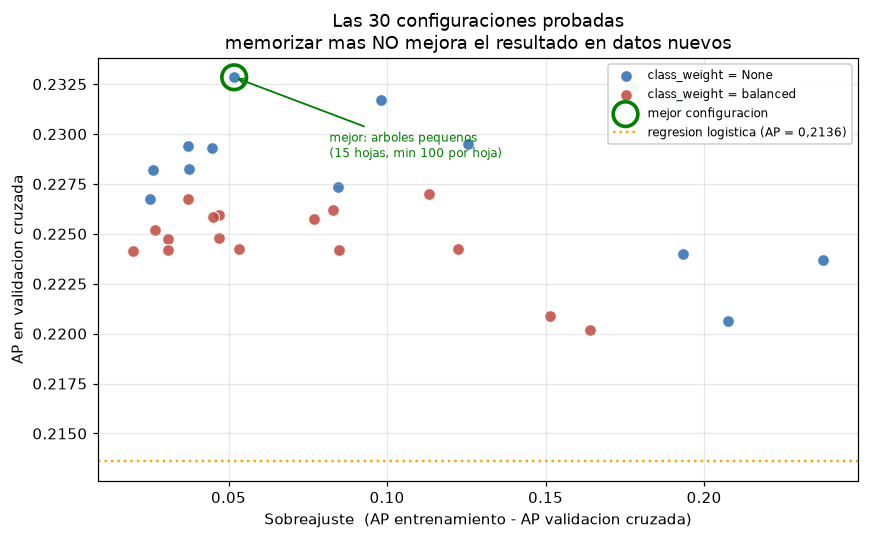

Eje X: cuanto memorizo el modelo. Mas a la derecha = memorizo mas.
Eje Y: que tan bien le fue en datos nuevos. Mas arriba = mejor.

La nube es casi PLANA: memorizar el triple no mejora nada en datos nuevos.


In [8]:
# Grafica: sobreajuste contra capacidad de generalizar
fig, ax = plt.subplots(figsize=(8, 5))
es_bal = res.param_modelo__class_weight.astype(str) == "balanced"

ax.scatter(res.sobreajuste[~es_bal], res.mean_test_score[~es_bal], c="#2B6CB0", s=60,
           alpha=.85, edgecolors="white", linewidths=.8, label="class_weight = None")
ax.scatter(res.sobreajuste[es_bal],  res.mean_test_score[es_bal],  c="#C0483C", s=60,
           alpha=.85, edgecolors="white", linewidths=.8, label="class_weight = balanced")

mejor = res.iloc[0]
ax.scatter([mejor.sobreajuste], [mejor.mean_test_score], s=260, facecolors="none",
           edgecolors="green", linewidths=2.4, zorder=5, label="mejor configuracion")
ax.annotate("mejor: arboles pequenos\n(15 hojas, min 100 por hoja)",
            xy=(mejor.sobreajuste, mejor.mean_test_score),
            xytext=(mejor.sobreajuste + 0.03, mejor.mean_test_score - 0.004),
            fontsize=8, color="green",
            arrowprops=dict(arrowstyle="->", color="green", lw=1.2))

ax.axhline(0.2136, ls=":", c="orange", lw=1.6, label="regresion logistica (AP = 0,2136)")
ax.set_xlabel("Sobreajuste  (AP entrenamiento - AP validacion cruzada)")
ax.set_ylabel("AP en validacion cruzada")
ax.set_title("Las 30 configuraciones probadas\nmemorizar mas NO mejora el resultado en datos nuevos")
ax.legend(fontsize=8, loc="upper right", framealpha=.95)
ax.grid(alpha=.3)
plt.tight_layout()
plt.savefig(FIGURAS / "03_sobreajuste.png", bbox_inches="tight", dpi=150)
plt.show()

print("Eje X: cuanto memorizo el modelo. Mas a la derecha = memorizo mas.")
print("Eje Y: que tan bien le fue en datos nuevos. Mas arriba = mejor.")
print("\nLa nube es casi PLANA: memorizar el triple no mejora nada en datos nuevos.")

## 6. El modelo elegido, evaluado en validación

Hasta ahora todo se midió **dentro del entrenamiento** (con validación cruzada). Ahora se mide
el modelo elegido sobre el conjunto de **validación**, que no participó en la búsqueda.

In [9]:
mejor_modelo = busqueda.best_estimator_
prob_gb = mejor_modelo.predict_proba(X_va)[:, 1]

ap_gb  = average_precision_score(y_va, prob_gb)
auc_gb = roc_auc_score(y_va, prob_gb)

print(f"AP media en validacion cruzada : {busqueda.best_score_:.4f}")
print(f"AP en validacion               : {ap_gb:.4f}")
print(f"ROC-AUC en validacion          : {auc_gb:.4f}")
print(f"Arboles usados                 : {mejor_modelo.named_steps['modelo'].n_iter_}")

AP media en validacion cruzada : 0.2328
AP en validacion               : 0.2238
ROC-AUC en validacion          : 0.6660
Arboles usados                 : 135


> **Nota honesta:** la AP de la validación cruzada (0,2328) queda por encima de la AP en
> validación (0,2238). Es normal y conviene decirlo: la configuración se **eligió** por su
> resultado en esa validación cruzada, así que ese número lleva algo de optimismo. **El valor
> que vale es el de validación**, medido sobre datos que no intervinieron en la elección.

## 7. Comparación con los modelos del Notebook 02

In [10]:
comparacion = pd.DataFrame([
    {"modelo": "Mayoritario",                  "AP": PREVALENCIA, "ROC_AUC": 0.5000},
    {"modelo": "Regresion logistica",          "AP": 0.2136,      "ROC_AUC": 0.6540},
    {"modelo": "Gradient Boosting por defecto","AP": ap_base,     "ROC_AUC": auc_base},
    {"modelo": "Gradient Boosting ajustado",   "AP": ap_gb,       "ROC_AUC": auc_gb},
]).set_index("modelo")

comparacion["AP_sobre_prevalencia"] = (comparacion.AP / PREVALENCIA).round(2)
comparacion["mejora_vs_logistica_%"] = (100*(comparacion.AP - 0.2136)/0.2136).round(1)
display(comparacion.round(4))

,AP,ROC_AUC,AP_sobre_prevalencia,mejora_vs_logistica_%
modelo,,,,
Mayoritario,0.1139,0.5000,1.00,-46.7
Regresion logistica,0.2136,0.6540,1.88,0.0
Gradient Boosting por defecto,0.2192,0.6621,1.93,2.6
Gradient Boosting ajustado,0.2238,0.6660,1.97,4.8


### Lectura de la comparación

**El Gradient Boosting ajustado es el mejor modelo**, pero la mejora sobre la regresión
logística es **modesta**: alrededor de un 5 % en AP y 0,012 en ROC-AUC.

**Eso no es un fracaso: es exactamente lo que predecía el estado del arte de la Fase 1.**

> Frizzell et al. (2017) compararon regresión logística con Random Forest y Gradient Boosting en
> 56.477 pacientes y encontraron un desempeño **similar y limitado**: estadístico C de ≈ 0,61
> para Gradient Boosting y ≈ 0,62 para regresión logística.

Nuestros resultados (0,654 y 0,666) están en ese mismo rango y reproducen el mismo patrón: **el
modelo más complejo gana, pero por poco**. La conclusión metodológica es que *la limitación está
en la información disponible, no en el algoritmo*. El archivo de UCI es una tabla resumida sin
variables sociales ni de seguimiento posterior al egreso.

Esto justifica, a posteriori, la decisión de la Fase 1 de **incluir un modelo sencillo como
comparación** y no dar por hecho que el algoritmo más complejo sería superior.

## 8. Guardar el modelo y los resultados

In [11]:
REPORTES = BASE / "reports"

joblib.dump(mejor_modelo, MODELOS / "gradient_boosting_ajustado.joblib")
np.save(PROCESSED / "prob_val_gradient_boosting.npy", prob_gb)
tabla.round(6).to_csv(REPORTES / "busqueda_03_hiperparametros.csv", index=False)
comparacion.round(6).to_csv(REPORTES / "metricas_03_comparacion.csv")

with open(REPORTES / "mejores_hiperparametros.json", "w", encoding="utf-8") as f:
    json.dump({k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()},
              f, indent=2, ensure_ascii=False)

print("Guardado:")
for ruta in [MODELOS / "gradient_boosting_ajustado.joblib",
             REPORTES / "busqueda_03_hiperparametros.csv",
             REPORTES / "metricas_03_comparacion.csv",
             REPORTES / "mejores_hiperparametros.json",
             FIGURAS  / "03_sobreajuste.png"]:
    print("  ", ruta.name)

Guardado:
   gradient_boosting_ajustado.joblib
   busqueda_03_hiperparametros.csv
   metricas_03_comparacion.csv
   mejores_hiperparametros.json
   03_sobreajuste.png


---

## Resumen

| Modelo | AP | ROC-AUC | AP / prevalencia |
|---|---|---|---|
| Mayoritario | 0,1139 | 0,500 | 1,00 × |
| Regresión logística | 0,2136 | 0,654 | 1,88 × |
| Gradient Boosting por defecto | 0,2192 | 0,662 | 1,92 × |
| **Gradient Boosting ajustado** | **0,2238** | **0,666** | **1,96 ×** |

### Configuración elegida

```
learning_rate      = 0.05      max_leaf_nodes    = 15
min_samples_leaf   = 100       l2_regularization = 0.5
max_features       = 0.8       class_weight      = None
```

### Lo que quedó documentado

1. **30 combinaciones probadas** con validación cruzada de 5 pliegues agrupada por paciente.
2. **Ganó la configuración más simple.** Las que hacían árboles grandes llegaban a AP 0,42 en
   entrenamiento pero no mejoraban en datos nuevos: memorizaban.
3. **Balancear no ayudó**, igual que en el Notebook 02. La peor de las 30 usaba `balanced`.
4. **La mejora sobre la regresión logística es de ~5 %**, coherente con Frizzell et al. (2017).

**Siguiente:** `04_evaluacion_comparada.ipynb` — elección del umbral, calibración, matrices de
confusión y la evaluación única sobre el conjunto de prueba.